# Task 1.3: Monte Carlo propagation of the OD normalization (round 1)

Draft. Same measurement model as task 1.2: transfer culture into the destination well, add media, $C_{final} = C_0 V_{transfer}/(V_{transfer}+V_d)$. Each dispense delivers $\tilde v(1+\varepsilon_{systematic}+\varepsilon_{random})$: one bias per run (Uniform ±8 %, shared by every dispense), one random error per dispense (Normal, sd 3.5 %).

## 1. Synthetic plate of starting ODs

In [1]:
import numpy as np
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from od_norm import normalize_plate, plot_od_flow, plot_volume_flow  # simulation loop and flow figures (src/od_norm.py)
np.random.seed(42)
FIG = Path("../figures")  # saved figures for the report (Part1/figures)
FIG.mkdir(parents=True, exist_ok=True)

# Make synthetic plate: starting OD C_0 of each well, observed range ~1.05-1.8
plate = np.random.uniform(low=1.05, high=1.8, size=(8, 12))

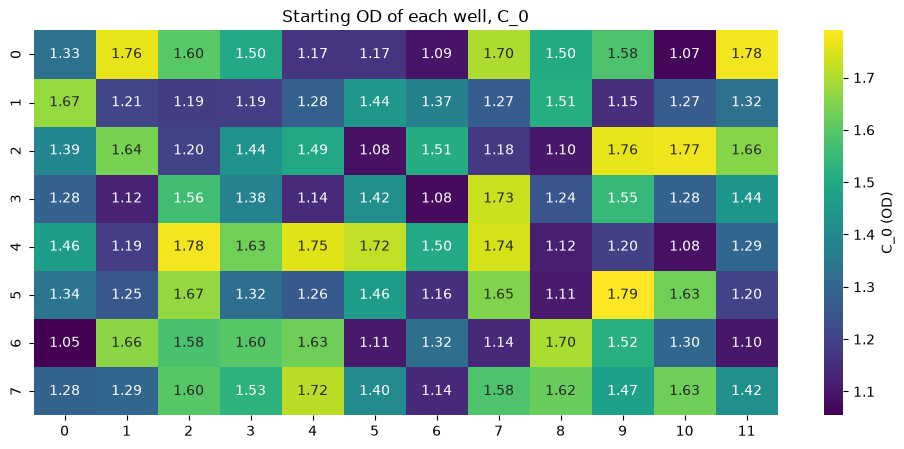

In [2]:
plt.figure(figsize=(12, 5))
sns.heatmap(plate, annot=True, fmt=".2f", cmap="viridis", cbar_kws={"label": "C_0 (OD)"})
plt.title("Starting OD of each well, C_0")
plt.savefig(FIG / "1-3_starting-od.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Inputs (same as the task 1.2 budget)

In [3]:
C_target = 1.0        # target OD
V_transfer = 100.0    # nominal transfer volume (uL)
tip = 20.0            # largest dispense (uL), 20 uL tip
err_rand = 0.035            # random error: 3.5 % CV (20 uL tip, 1 uL row) -> sd of eps_random
err_sys = 0.08              # bias bound: +/- 8 % (rectangular)
N = 100_000           # Monte Carlo trials
u_sys = err_sys / np.sqrt(3)
pd.DataFrame({"standard uncertainty": [err_rand, u_sys]}, index=["u(eps_random) = CV", "u(eps_systematic) = err_sys/sqrt(3)"]).round(4)

,standard uncertainty
u(eps_random) = CV,0.0350
u(eps_systematic) = err_sys/sqrt(3),0.0462


## 3. Dispense plan for the budget scenario ($C_0 = 1.5$)

Greedy split of each step into dispenses no larger than the tip; weight = dispense volume / step volume.

In [4]:
C0 = 1.5
V_d = V_transfer * (C0 / C_target - 1)      # nominal media volume (uL)
plan_t = [tip] * int(V_transfer // tip) + ([V_transfer % tip] if V_transfer % tip > 0 else [])
plan_d = [tip] * int(V_d // tip) + ([V_d % tip] if V_d % tip > 0 else [])
w_t = np.array(plan_t) / V_transfer
w_d = np.array(plan_d) / V_d
pd.DataFrame({"step": ["transfer"] * len(plan_t) + ["dilution"] * len(plan_d),
              "nominal volume (uL)": plan_t + plan_d,
              "weight w": np.r_[w_t, w_d]})

,step,nominal volume (uL),weight w
0,transfer,20.0,0.2
1,transfer,20.0,0.2
2,transfer,20.0,0.2
3,transfer,20.0,0.2
4,transfer,20.0,0.2
5,dilution,20.0,0.4
6,dilution,20.0,0.4
7,dilution,10.0,0.2


## 4. Sample the input distributions

One bias per run, shared by the transfer and the dilution (same pipette, $r=+1$); one random error per dispense.

In [5]:
bias = np.random.uniform(-err_sys, err_sys, N)                      # (N,)
rand_t = np.random.normal(0, err_rand, (N, len(plan_t)))      # (N, 5)
rand_d = np.random.normal(0, err_rand, (N, len(plan_d)))      # (N, 3)

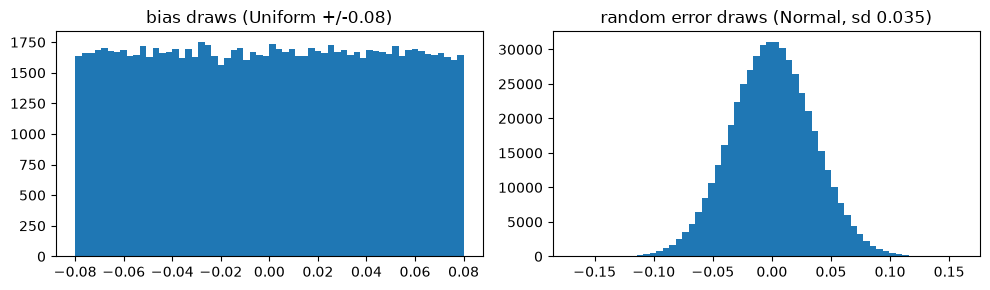

In [6]:
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1); plt.hist(bias, bins=60); plt.title("bias draws (Uniform +/-0.08)")
plt.subplot(1, 2, 2); plt.hist(rand_t.ravel(), bins=60); plt.title("random error draws (Normal, sd 0.035)")
plt.tight_layout(); plt.savefig(FIG / "1-3_input-draws.png", dpi=200, bbox_inches="tight"); plt.show()

## 5. Push every trial through the exact model (no linearization)

In [7]:
eps_t = bias + rand_t @ w_t                 # transfer step error
eps_d = bias + rand_d @ w_d                 # dilution step error
V_t_true = V_transfer * (1 + eps_t)         # true culture volume
V_d_true = V_d * (1 + eps_d)                # true media volume
C_final = C0 * V_t_true / (V_t_true + V_d_true)
C_final[:5]

array([0.99321498, 1.00587589, 1.00000355, 1.00325657, 0.99013877])

## 6. Look at one trial

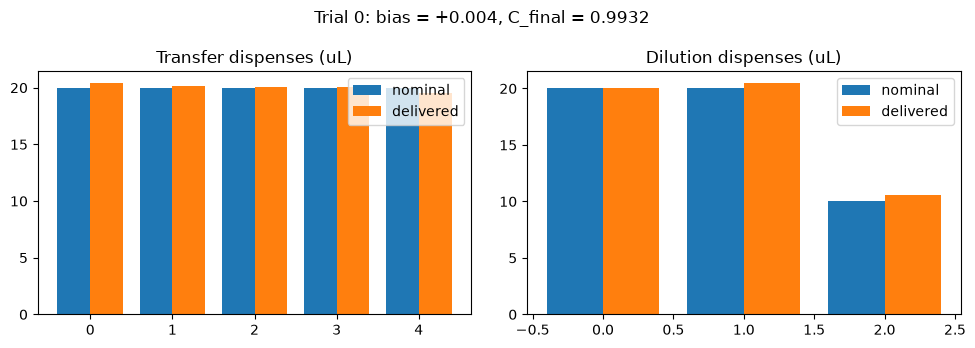

In [8]:
k = 0
plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1)
plt.bar(np.arange(len(plan_t)) - 0.2, plan_t, 0.4, label="nominal")
plt.bar(np.arange(len(plan_t)) + 0.2, np.array(plan_t) * (1 + bias[k] + rand_t[k]), 0.4, label="delivered")
plt.title("Transfer dispenses (uL)"); plt.legend()
plt.subplot(1, 2, 2)
plt.bar(np.arange(len(plan_d)) - 0.2, plan_d, 0.4, label="nominal")
plt.bar(np.arange(len(plan_d)) + 0.2, np.array(plan_d) * (1 + bias[k] + rand_d[k]), 0.4, label="delivered")
plt.title("Dilution dispenses (uL)"); plt.legend()
plt.suptitle(f"Trial {k}: bias = {bias[k]:+.3f}, C_final = {C_final[k]:.4f}")
plt.tight_layout(); plt.savefig(FIG / "1-3_one-trial-dispenses.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Result and comparison with the analytic $u_c$ (task 1.2)

In [9]:
u_c_analytic = C_target * (1 - C_target / C0) * err_rand * np.sqrt(np.sum(w_t**2) + np.sum(w_d**2))
sd_mc = C_final.std(ddof=1)
pd.DataFrame({"value": [N, C_final.mean(), sd_mc, u_c_analytic, sd_mc / u_c_analytic,
                        np.mean(np.abs(C_final - C_target) > 0.02)]},
             index=["trials N", "mean C_final (OD)", "Monte Carlo sd (OD)", "analytic u_c, task 1.2 (OD)",
                    "ratio MC / analytic", "P(|C_final - 1| > 0.02)"]).round(5)

,value
trials N,100000.00000
mean C_final (OD),0.99998
Monte Carlo sd (OD),0.00877
"analytic u_c, task 1.2 (OD)",0.00873
ratio MC / analytic,1.00405
P(|C_final - 1| > 0.02),0.02298


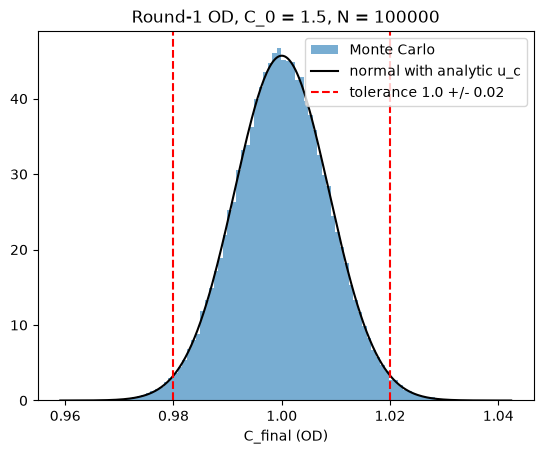

In [10]:
x = np.linspace(C_final.min(), C_final.max(), 300)
plt.hist(C_final, bins=100, density=True, alpha=0.6, label="Monte Carlo")
plt.plot(x, np.exp(-0.5 * ((x - C_target) / u_c_analytic)**2) / (u_c_analytic * np.sqrt(2 * np.pi)), "k", label="normal with analytic u_c")
plt.axvline(C_target - 0.02, color="r", ls="--", label="tolerance 1.0 +/- 0.02"); plt.axvline(C_target + 0.02, color="r", ls="--")
plt.xlabel("C_final (OD)"); plt.legend(); plt.title(f"Round-1 OD, C_0 = {C0}, N = {N}")
plt.savefig(FIG / "1-3_cfinal-histogram.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Convergence check

Running sd against trial count, then 5 independent seeds.

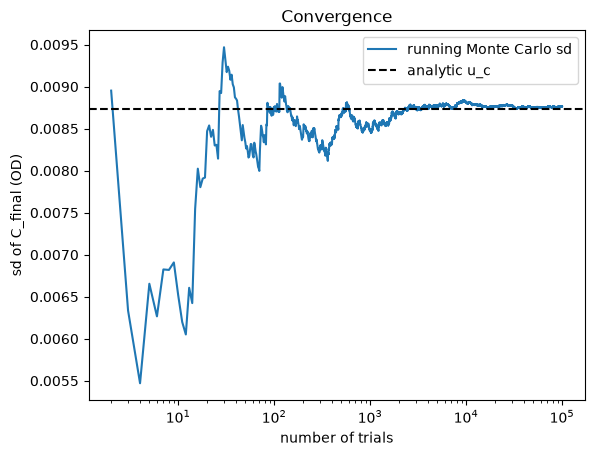

In [11]:
n = np.arange(2, N + 1)
s1 = np.cumsum(C_final)[1:]; s2 = np.cumsum(C_final**2)[1:]
running_sd = np.sqrt((s2 - s1**2 / n) / (n - 1))
plt.semilogx(n, running_sd, label="running Monte Carlo sd")
plt.axhline(u_c_analytic, color="k", ls="--", label="analytic u_c")
plt.xlabel("number of trials"); plt.ylabel("sd of C_final (OD)"); plt.legend(); plt.title("Convergence")
plt.savefig(FIG / "1-3_convergence.png", dpi=200, bbox_inches="tight")
plt.show()

In [12]:
sds = []
for seed in range(5):
    rng = np.random.default_rng(seed)
    b = rng.uniform(-err_sys, err_sys, N)
    et = b + rng.normal(0, err_rand, (N, len(plan_t))) @ w_t
    ed = b + rng.normal(0, err_rand, (N, len(plan_d))) @ w_d
    c = C0 * V_transfer * (1 + et) / (V_transfer * (1 + et) + V_d * (1 + ed))
    sds.append(c.std(ddof=1))
pd.DataFrame({"sd of C_final (OD)": sds}, index=pd.Index(range(5), name="seed")).round(6)

,sd of C_final (OD)
seed,
0,0.008767
1,0.008766
2,0.008781
3,0.008767
4,0.008770


In [13]:
pd.DataFrame({"value (OD)": [np.mean(sds), np.std(sds, ddof=1), u_c_analytic]},
             index=["mean over seeds", "spread between seeds (sd)", "analytic u_c"]).round(6)

,value (OD)
mean over seeds,0.008770
spread between seeds (sd),0.000006
analytic u_c,0.008731


## 9. Whole plate, one run (one pipette, so one bias for every well)

In [14]:
plate_final, V_t, V_d = [r[0] for r in normalize_plate(plate, tip, err_rand, err_sys)]   # one run: one pipette bias for every well
out = np.abs(plate_final - C_target) > 0.02
pd.DataFrame({"wells": [out.sum(), plate.size]}, index=["outside 1.0 +/- 0.02", "total"])

,wells
outside 1.0 +/- 0.02,1
total,96


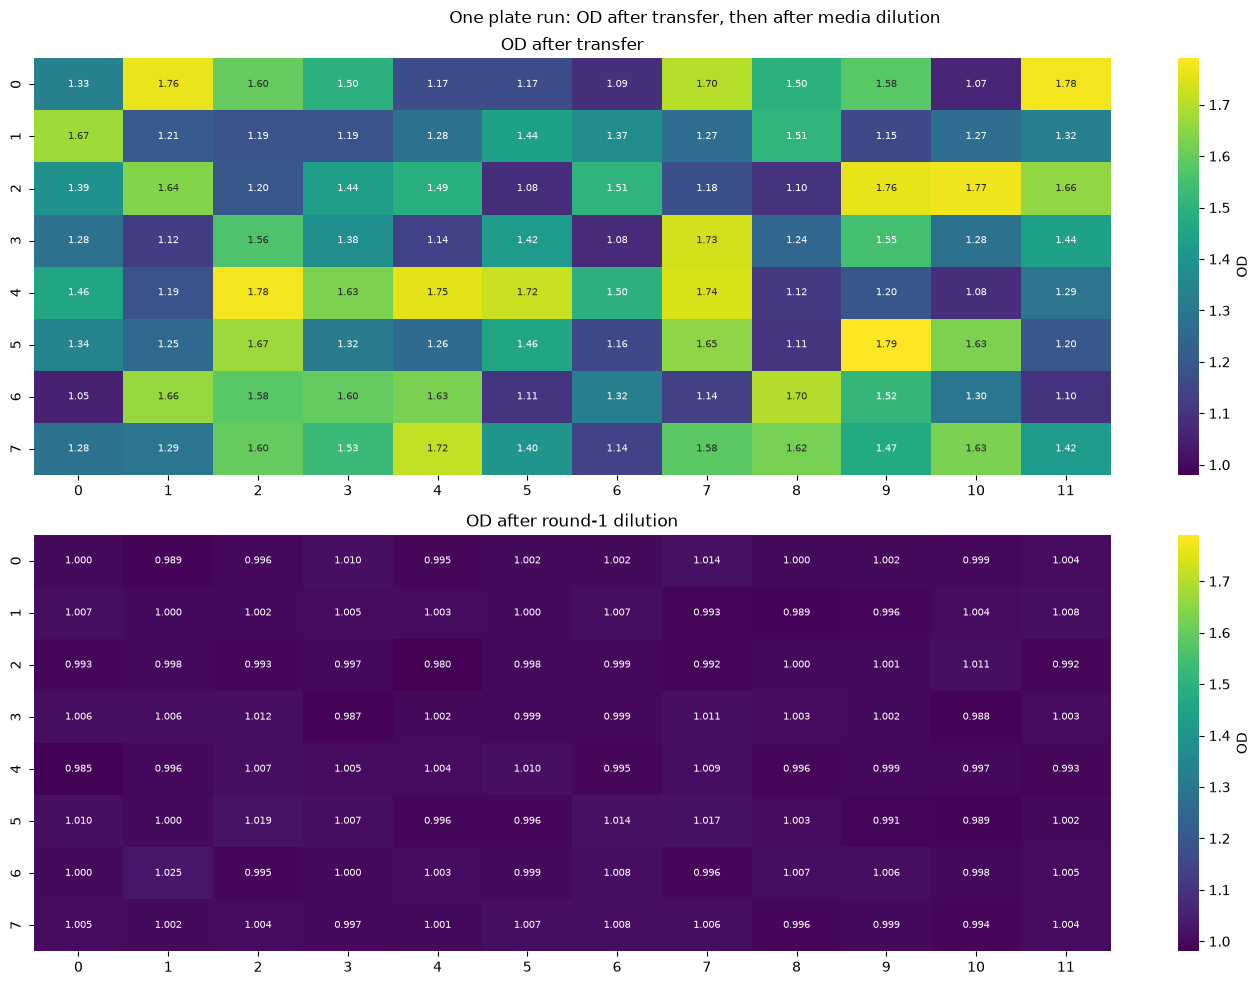

In [15]:
plot_od_flow(plate, plate_final, "One plate run: OD after transfer, then after media dilution",
             save=FIG / "1-3_plate-od-flow.png")

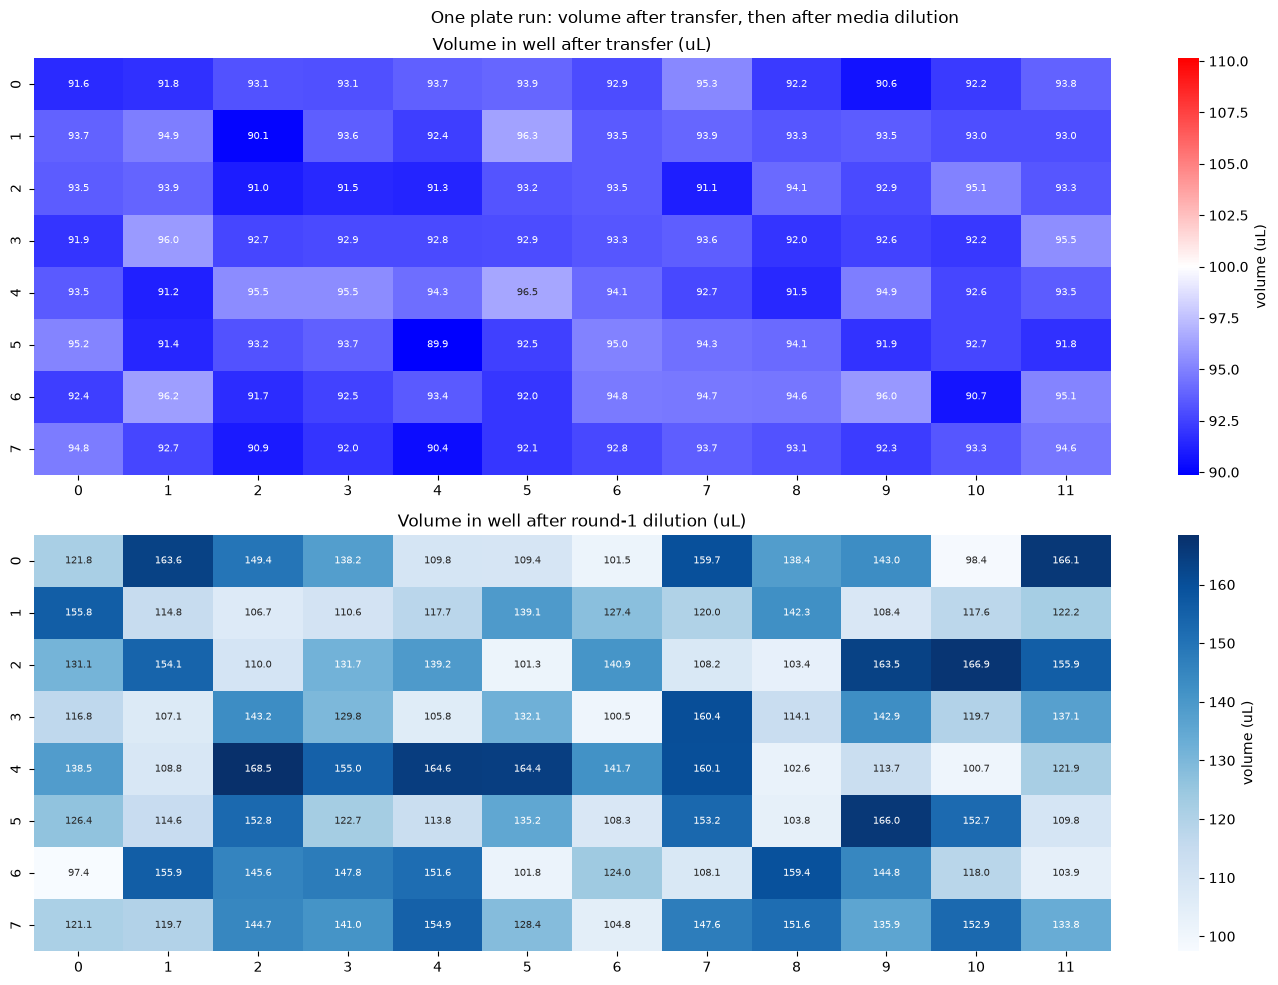

In [16]:
plot_volume_flow(V_t, V_d, V_transfer, "One plate run: volume after transfer, then after media dilution",
                 save=FIG / "1-3_plate-volume-flow.png")

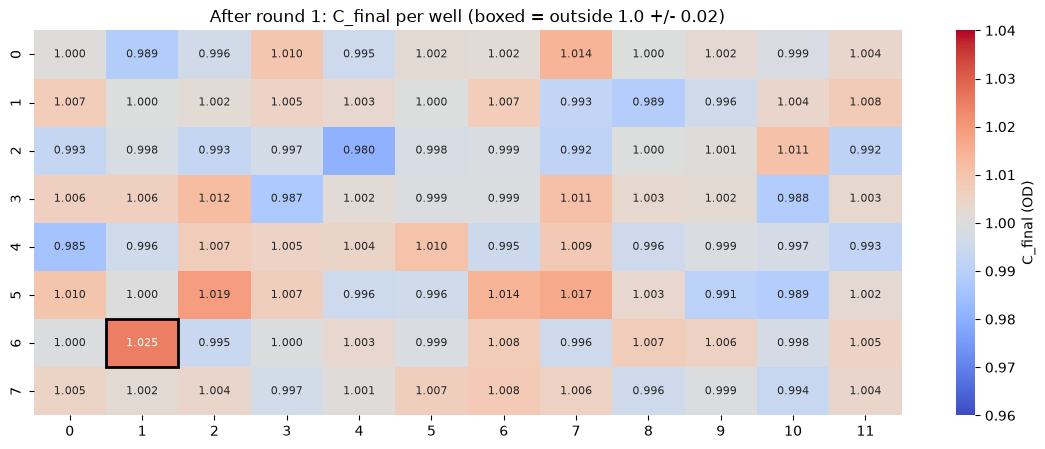

In [17]:
plt.figure(figsize=(14, 5))
sns.heatmap(plate_final, annot=True, fmt=".3f", annot_kws={"size": 8}, cmap="coolwarm", center=C_target, vmin=0.96, vmax=1.04,
            cbar_kws={"label": "C_final (OD)"})
for i, j in zip(*np.where(out)):
    plt.gca().add_patch(plt.Rectangle((j, i), 1, 1, fill=False, ec="k", lw=2))
plt.title("After round 1: C_final per well (boxed = outside 1.0 +/- 0.02)")
plt.savefig(FIG / "1-3_plate-cfinal.png", dpi=200, bbox_inches="tight")
plt.show()

## 10. Plate Monte Carlo: spread and out-of-tolerance probability per well

In [18]:
R = 5000
cf = normalize_plate(plate, tip, err_rand, err_sys, runs=R)[0]       # (R, 8, 12): one pipette bias per plate run
sd_well = cf.std(axis=0, ddof=1)
pout_well = np.mean(np.abs(cf - C_target) > 0.02, axis=0)

uc_well = np.zeros_like(plate)                           # analytic u_c per well (task 1.2 formula)
for (i, j), c0 in np.ndenumerate(plate):
    vd = V_transfer * (c0 / C_target - 1)
    p_t = np.array([tip] * int(V_transfer // tip) + ([V_transfer % tip] if V_transfer % tip > 1e-9 else []))
    p_d = np.array([tip] * int(vd // tip) + ([vd % tip] if vd % tip > 1e-9 else []))
    uc_well[i, j] = C_target * (1 - C_target / c0) * err_rand * np.sqrt(np.sum((p_t / p_t.sum())**2) + np.sum((p_d / p_d.sum())**2))
pd.DataFrame({"value": [R, np.max(np.abs(sd_well / uc_well - 1)), pout_well.sum()]},
             index=["plate runs R", "max |MC sd / analytic u_c - 1| over wells",
                    "expected wells outside tolerance per plate (of 96)"]).round(3)

,value
plate runs R,5000.000
max |MC sd / analytic u_c - 1| over wells,0.026
expected wells outside tolerance per plate (of 96),1.823


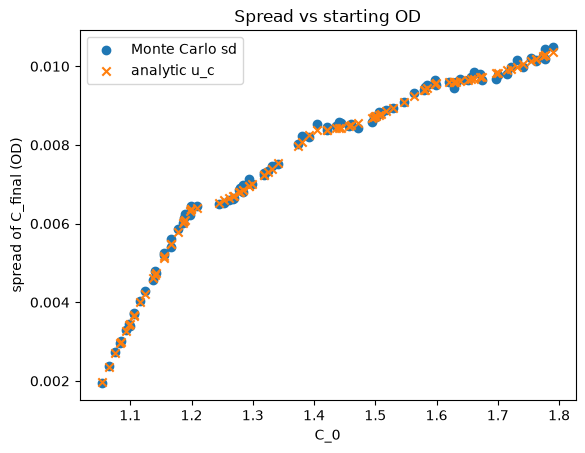

In [19]:
plt.scatter(plate.ravel(), sd_well.ravel(), label="Monte Carlo sd")
plt.scatter(plate.ravel(), uc_well.ravel(), marker="x", label="analytic u_c")
plt.xlabel("C_0"); plt.ylabel("spread of C_final (OD)"); plt.legend(); plt.title("Spread vs starting OD")
plt.savefig(FIG / "1-3_spread-vs-c0.png", dpi=200, bbox_inches="tight")
plt.show()

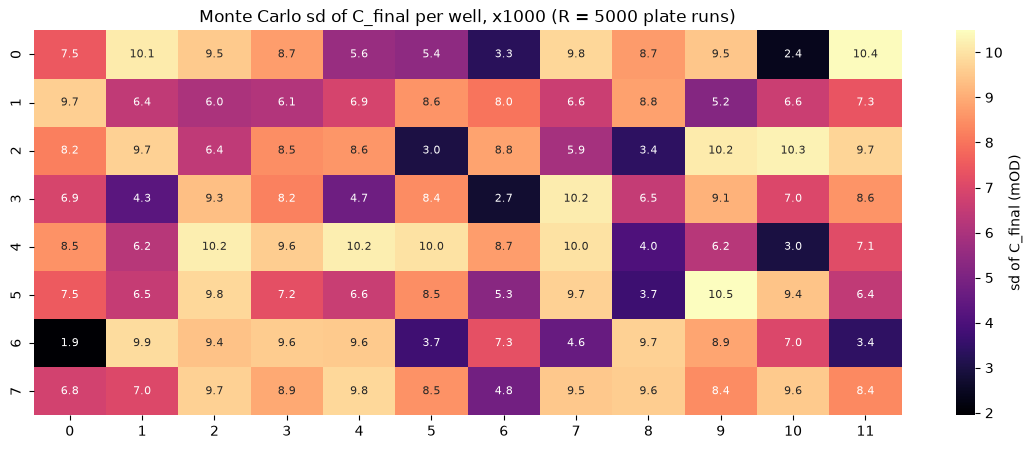

In [20]:
plt.figure(figsize=(14, 5))
sns.heatmap(sd_well * 1000, annot=True, fmt=".1f", annot_kws={"size": 8}, cmap="magma", cbar_kws={"label": "sd of C_final (mOD)"})
plt.title(f"Monte Carlo sd of C_final per well, x1000 (R = {R} plate runs)")
plt.savefig(FIG / "1-3_plate-sd.png", dpi=200, bbox_inches="tight")
plt.show()

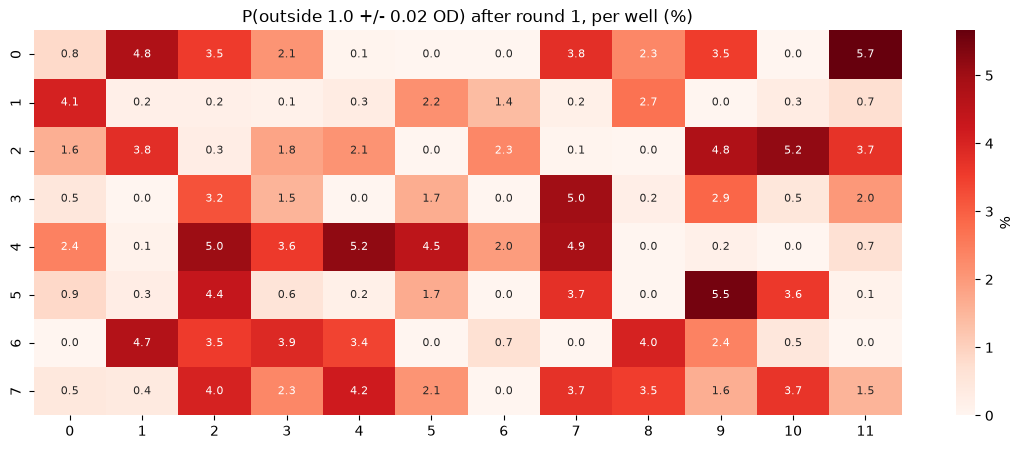

In [21]:
plt.figure(figsize=(14, 5))
sns.heatmap(pout_well * 100, annot=True, fmt=".1f", annot_kws={"size": 8}, cmap="Reds", cbar_kws={"label": "%"})
plt.title("P(outside 1.0 +/- 0.02 OD) after round 1, per well (%)")
plt.savefig(FIG / "1-3_plate-p-out.png", dpi=200, bbox_inches="tight")
plt.show()